Este código presenta explora la cantidad de clases dispoibles en el dataset
además de su distribución.

In [1]:
from pathlib import Path
from PIL import Image
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

In [2]:
class_names = {
    0: "Sin etiqueta",
    10: "Árboles",
    20: "Matorrales",
    30: "Pastizales",
    40: "Cultivos",
    50: "Zonas construidas",
    60: "Suelo desnudo / vegetación escasa",
    70: "Nieve y hielo",
    80: "Cuerpos de agua",
    90: "Humedales",
    95: "Manglares",
    100: "Musgos y líquenes"
}

In [3]:
MASK_DIR = Path.home() / "data" / "SatelliteSegmentation" / "masks"
mask_files = sorted(MASK_DIR.glob("*.png"))
print("Total de máscaras:", len(mask_files))

for file in mask_files[:5]:
    mask = np.array(Image.open(file))
    print(f"{file.name}: {np.unique(mask)}")

Total de máscaras: 790
0000_mask.png: [  0  10  30  40  50  60  80  90 100]
0001_mask.png: [10 30 40 50 60 80 90]
0002_mask.png: [10 30 40 50 60 80 90]
0003_mask.png: [10 30 50 80 90]
0004_mask.png: [10 30 40 50 60 80]


In [4]:
pixel_counts = Counter()
image_counts = Counter()

In [5]:
for file in mask_files:
    mask = np.array(Image.open(file))
    values, counts = np.unique(mask, return_counts=True)
    pixel_counts.update(dict(zip(values, counts)))
    image_counts.update(values.tolist())

total_pixels = sum(pixel_counts.values())

In [6]:
print(f"Total de máscaras: {len(mask_files)}")
print(f"Total de píxeles: {total_pixels:,}\n")

Total de máscaras: 790
Total de píxeles: 51,773,440



In [7]:
print(f"{'ID':<6}{'Clase':<38}{'Píxeles':>15}{'Porcentaje':>15}{'Imágenes':>12}")
print("-" * 86)
for class_id in sorted(pixel_counts):
    count = pixel_counts[class_id]
    percentage = (count / total_pixels) * 100

    print(
        f"{class_id:<6}"
        f"{class_names.get(class_id, 'Desconocida'):<38}"
        f"{count:>15,}"
        f"{percentage:>14.2f}%"
        f"{image_counts[class_id]:>12}"
    )

ID    Clase                                         Píxeles     Porcentaje    Imágenes
--------------------------------------------------------------------------------------
0     Sin etiqueta                                   10,752          0.02%          21
10    Árboles                                    36,560,738         70.62%         790
20    Matorrales                                      1,626          0.00%          25
30    Pastizales                                  4,801,317          9.27%         790
40    Cultivos                                    3,821,687          7.38%         577
50    Zonas construidas                           1,955,765          3.78%         716
60    Suelo desnudo / vegetación escasa              92,350          0.18%         587
70    Nieve y hielo                                      49          0.00%          15
80    Cuerpos de agua                             4,456,426          8.61%         753
90    Humedales                            

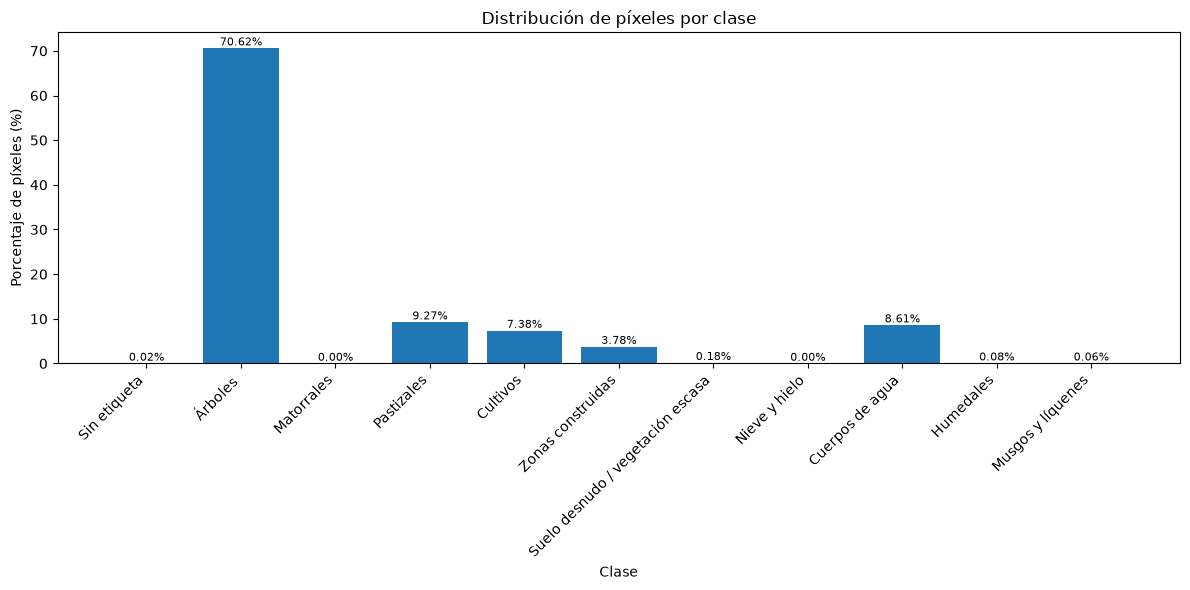

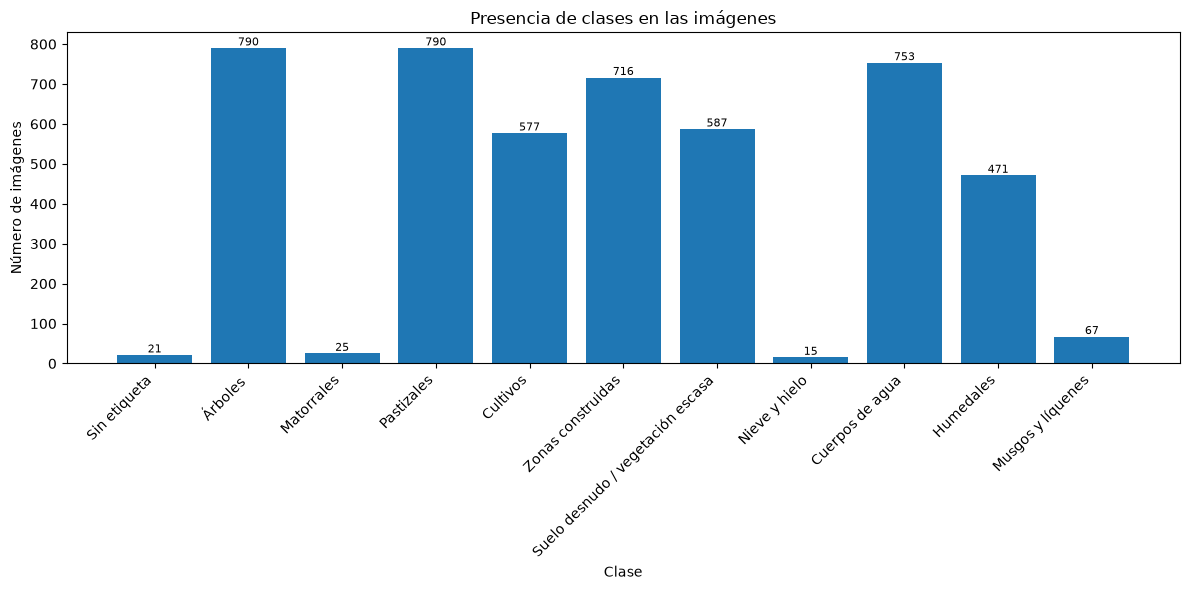

In [8]:
classes = sorted(pixel_counts.keys())

labels = [class_names.get(c, str(c)) for c in classes]
pixels = [pixel_counts[c] for c in classes]
images = [image_counts[c] for c in classes]

percentages = [(pixel_counts[c] / total_pixels) * 100 for c in classes]

plt.figure(figsize=(12, 6))
bars = plt.bar(labels, percentages)

plt.title("Distribución de píxeles por clase")
plt.xlabel("Clase")
plt.ylabel("Porcentaje de píxeles (%)")
plt.xticks(rotation=45, ha="right")

for bar, value in zip(bars, percentages):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=8)

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
bars = plt.bar(labels, images)

plt.title("Presencia de clases en las imágenes")
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=45, ha="right")

for bar, value in zip(bars, images):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom",
        fontsize=8)

plt.tight_layout()
plt.show()